# Prueba Intertrimestral

**Nombre: Pelayo**  
**Apellidos: González Martínez**  

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix


# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [5]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type == "classic":
        tarifa = 1 + 0.05*duration_min
    elif bike_type == "electric":
        tarifa = 1.5 + 0.08*duration_min
    else:
        raise ValueError("Tipo de bici erroneo")
    if is_member == True:
        return round(tarifa*0.8,2)
    else:
        return round(tarifa,2)

In [7]:
rental_fee(20, "classic", False)

2.0

b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [6]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    elif threshold/2 <= total_rentals < threshold:
        return "Media"
    else:
        return "Baja"

In [10]:
print(demand_label(2,7))
print(demand_label(3.75,7))
print(demand_label(10,7))

Baja
Media
Alta


c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [25]:
data = {
    "duration_min": [14, 23.3, 6.7, 45.0, 7.0, 30.6, 12.5, 60.0, 85.0, 22.0],
    "bike_type": ["electric", "electric", "classic", "classic", "classic", "classic", "electric", "electric", "classic", "electric"],
    "is_member": [False, False, True, True, False, True, True, False, True, False],
    "total_rentals": [70, 23, 33, 45, 5, 67, 32, 67, 7, 25]}
#Transformamos en Dataset
tripsDemo = pd.DataFrame(data)
#Añadimos columnas
tripsDemo["fee"] = tripsDemo.apply(
    lambda row: rental_fee(row["duration_min"], row["bike_type"], row["is_member"]), 
    axis=1)
tripsDemo["demand"] = tripsDemo.apply(
    lambda row: demand_label(row["total_rentals"], threshold=40), 
    axis=1)

print(tripsDemo)

   duration_min bike_type  is_member  total_rentals   fee demand
0          14.0  electric      False             70  2.62   Alta
1          23.3  electric      False             23  3.36  Media
2           6.7   classic       True             33  1.07  Media
3          45.0   classic       True             45  2.60   Alta
4           7.0   classic      False              5  1.35   Baja
5          30.6   classic       True             67  2.02   Alta
6          12.5  electric       True             32  2.00  Media
7          60.0  electric      False             67  6.30   Alta
8          85.0   classic       True              7  4.20   Baja
9          22.0  electric      False             25  3.26  Media


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [26]:
class MicromobilityTools:
    
    def _rental_fee(duration_min, bike_type, is_member):
        if bike_type == "classic":
            tarifa_base, coste_minuto = 1.00, 0.05
        elif bike_type == "electric":
            tarifa_base, coste_minuto = 1.50, 0.08
        else:
            raise ValueError("Invalid bike_type")
            
        coste = tarifa_base + (coste_minuto * duration_min)
        return round(coste * 0.8 if is_member else coste, 2)

    def _demand_label(total_rentals, threshold):
        if total_rentals >= threshold:
            return "Alta"
        elif total_rentals >= (threshold / 2):
            return "Media"
        else:
            return "Baja"

    def calculate_fees(self, duration_list, bike_list, member_list):
        return [self._rental_fee(d, b, m) for d, b, m in zip(duration_list, bike_list, member_list)]
    def label_demands(self, rentals_list, threshold):
        return [self._demand_label(r, threshold) for r in rentals_list]

## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [12]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv")
print(mobilityData.head())
print(f"Dimensiones (filas, columnas): {mobilityData.shape}")

              datetime  year  month  day  hour  weekday  season  is_holiday  \
0  2025-01-01 00:00:00  2025      1    1     0        2  Winter           1   
1  2025-01-01 01:00:00  2025      1    1     1        2  Winter           1   
2  2025-01-01 02:00:00  2025      1    1     2        2  Winter           1   
3  2025-01-01 03:00:00  2025      1    1     3        2  Winter           1   
4  2025-01-01 04:00:00  2025      1    1     4        2  Winter           1   

   is_weekend  is_workingday  ... wind_kmh  precip_mm  casual_users  \
0           0              0  ...      9.7        0.0             2   
1           0              0  ...      2.8        0.0             1   
2           0              0  ...      9.0        0.0             1   
3           0              0  ...      5.4        0.0             2   
4           0              0  ...      2.4        0.0             1   

   member_users  total_rentals  avg_trip_min  avg_distance_km  electric_share  \
0             8  

b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [27]:
def describeData(dataFrame):
    resumen = pd.DataFrame({
        'Tipo de dato': dataFrame.dtypes,
        'Número de nulos': dataFrame.isnull().sum(),
        'Porcentaje de nulos': (dataFrame.isnull().sum() / len(dataFrame)) * 100})
    return resumen

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [28]:
describeData(mobilityData)

,Tipo de dato,Número de nulos,Porcentaje de nulos
datetime,str,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
day,int64,0,0.000000
hour,int64,0,0.000000
weekday,int64,0,0.000000
season,str,0,0.000000
is_holiday,int64,0,0.000000
is_weekend,int64,0,0.000000
is_workingday,int64,0,0.000000


Las variables que tienen más factores faltantes son *humidity* y *avg_trip_min*, seguidas por *wind_kmh* y *electric_share*. Hay varias opciones para modelar estas variables. Se pueden normalizar los datos existentes o se pueden predecir los datos faltantes. Depende del problema que se este planteando, convendrá más una solución u otra. 

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


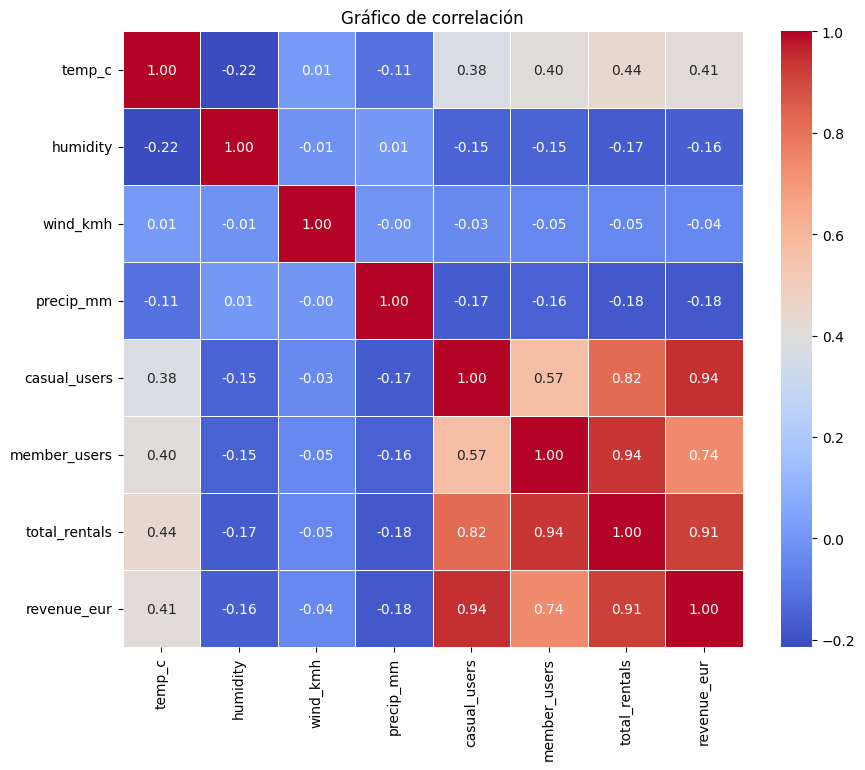

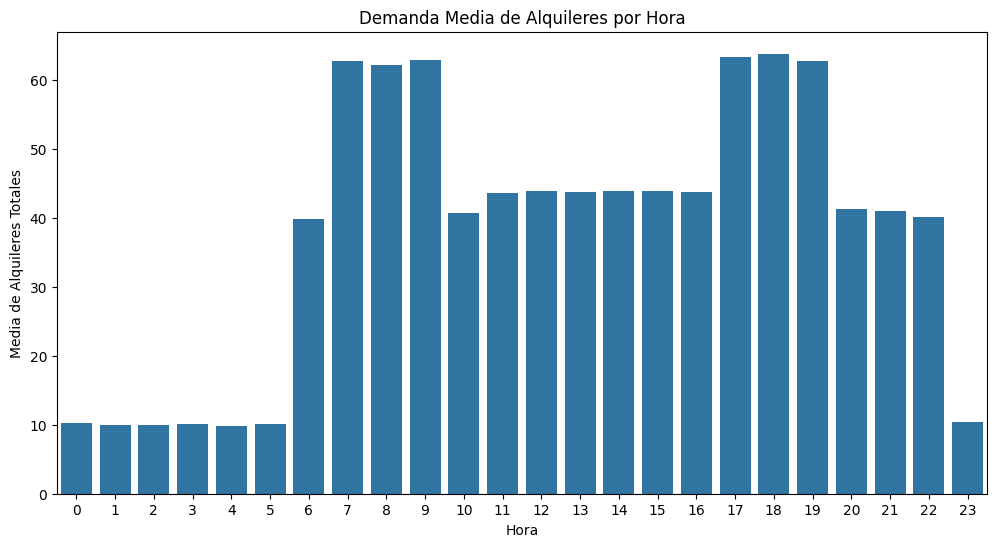

In [34]:
variables_numericas = ['temp_c', 'humidity', 'wind_kmh', 'precip_mm', 
                      'casual_users', 'member_users', 'total_rentals', 'revenue_eur']

plt.figure(figsize=(10, 8))
matriz_correlacion = mobilityData[variables_numericas].corr()
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Gráfico de correlación')
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=mobilityData, x='hour', y='total_rentals', errorbar=None)
plt.title('Demanda Media de Alquileres por Hora')
plt.xlabel('Hora')
plt.ylabel('Media de Alquileres Totales')
plt.show()

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [35]:
targetVar = "total_rentals"
pred_vars = ["hour", "temp_c", "humidity", "precip_mm", "is_workingday"]

X = mobilityData[pred_vars].copy()
y = mobilityData[targetVar]
X = X.fillna(X.median())

b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [37]:
linreg_model = LinearRegression()
linreg_model.fit(X_train, y_train)

y_pred_linreg = linreg_model.predict(X_test)
r2_linreg = r2_score(y_test, y_pred_linreg)
mse_linreg = mean_squared_error(y_test, y_pred_linreg)
print(f"Regresión Lineal -> R2: {r2_linreg:.4f}, MSE: {mse_linreg:.2f}")

Regresión Lineal -> R2: 0.3206, MSE: 408.66


d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [40]:
RandomForest = RandomForestRegressor(random_state=42)
RandomForest.fit(X_train, y_train)

RFy_pred = RandomForest.predict(X_test)
RF_r2 = r2_score(y_test, RFy_pred)
RF_mse = mean_squared_error(y_test, RFy_pred)
print(f"Random Forest -> R2: {RF_r2:.4f}, MSE: {RF_mse:.2f}")

Random Forest -> R2: 0.8831, MSE: 70.34


Funciona mejor RF gracias a su capacidad de captar relaciones no-lineales.  

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [41]:
balance_clases = mobilityData['high_demand'].value_counts(normalize=True)
print("Balance de clases (proporción):\n", balance_clases)

Balance de clases (proporción):
 high_demand
0    0.688984
1    0.311016
Name: proportion, dtype: float64


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [42]:
variables_cont = ["hour", "temp_c", "humidity", "precip_mm", "is_workingday"]
X = mobilityData[variables_cont].copy()
y = mobilityData['high_demand']

X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


In [44]:
y_pred = log_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matriz de Confusión:\n", conf_matrix)

Accuracy: 0.7580
Matriz de Confusión:
 [[3299  326]
 [ 946  685]]


d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


In [47]:
factores = pd.DataFrame({
    'Factor': variables_cont,
    'Coeficiente': log_model.coef_[0]
}).sort_values(by='Coeficiente', ascending=False)

print(factores)

          Factor  Coeficiente
1         temp_c     0.091970
0           hour     0.052506
2       humidity    -0.015021
4  is_workingday    -0.496792
3      precip_mm    -2.351602


## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



Según la regresión logistica elaborada al final, la temperatura y la hora del dia son unos grandes indicadores de la demanda de alquiler de bicicletas. A su vez, las precipitaciones, los días laborables y la humedad también son factores muy influyentes que empujan más hacia el otro lado. El módelo del cual se han observado mejores resultados es el RandomForest con un coeficiente de determinacion de 0.8831 y un MSE de 70.34. Su superioridad se debe a la que RandomForest puede captar fácilmente las relaciones no lineales y demás interacciones complejas entre los datos de la movilidad. Para fitiras predicciones se propone añadir otras variables como huelgas, eventos de ocio (como partidos de fútbol) o obras en las carreteras, que tienen un gran impacto en la movilidad. A su vez, entrenar al modelo con datos de otras ciudades o con un histórico de precios, mejoraría la capacidad de generalización de este. 